<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/standard_model/sm_colab_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Standard Model* — `sm_colab_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Standard Model — Chapter Visualizations
**PSE Lab | SeoulTech**

Seven interactive visualizations — one key figure per chapter of the Standard Model course (Tong, DAMTP Cambridge).

| # | Visualization | Chapter |
|---|---|---|
| 1 | Lorentz Representations & SM Particle Spectrum | Ch 1: Symmetries |
| 2 | Mexican Hat Potential & Higgs Mechanism (3D) | Ch 2: Broken Symmetries |
| 3 | Running Coupling $\alpha_s(\mu)$ & QCD Phase Structure | Ch 3: Strong Force |
| 4 | Triangle Anomaly & $\pi^0\to\gamma\gamma$ Prediction vs $N_c$ | Ch 4: Anomalies |
| 5 | $Z$ Partial Widths & EW Precision Measurements | Ch 5: Electroweak |
| 6 | CKM Unitarity Triangle & $B$-factory CP Asymmetry | Ch 6: Flavour |
| 7 | Neutrino Oscillation Probabilities & Seesaw Scales | Ch 7: Neutrinos |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Ellipse, Arc
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings('ignore')

# ── Consistent dark style (teal accent — SM series) ──────────────────────
BG    = '#0d1117'
SURF  = '#161b22'
EDGE  = '#30363d'
TEXT  = '#e6edf3'
DIM   = '#8b949e'
TEAL  = '#2ec4b6'
BLUE  = '#7ec8e3'
GREEN = '#90ee90'
RED   = '#e07070'
PURP  = '#c792ea'
YELL  = '#f9c74f'
ORAN  = '#e8a838'
PINK  = '#ff79c6'

plt.rcParams.update({
    'figure.facecolor': BG,   'axes.facecolor': SURF,
    'axes.edgecolor':   EDGE,  'axes.labelcolor': TEXT,
    'xtick.color': DIM,        'ytick.color': DIM,
    'text.color':  TEXT,       'grid.color': EDGE,
    'grid.alpha':  0.35,       'lines.linewidth': 2.2,
    'axes.titlesize': 13,      'axes.titleweight': 'bold',
    'axes.titlecolor': TEAL,   'figure.dpi': 110,
    'legend.framealpha': 0.3,  'legend.edgecolor': EDGE,
})

print('Setup complete — Standard Model visualizations ready.')

Setup complete — Standard Model visualizations ready.


---
## Visualization 1 · Lorentz Representations & SM Particle Spectrum (Ch 1)

**Left**: The $(j_+, j_-)$ representation lattice — each node shows the particle type and field dimension  
**Right**: SM particle spectrum arranged by spin and mass — quarks, leptons, gauge bosons, and Higgs

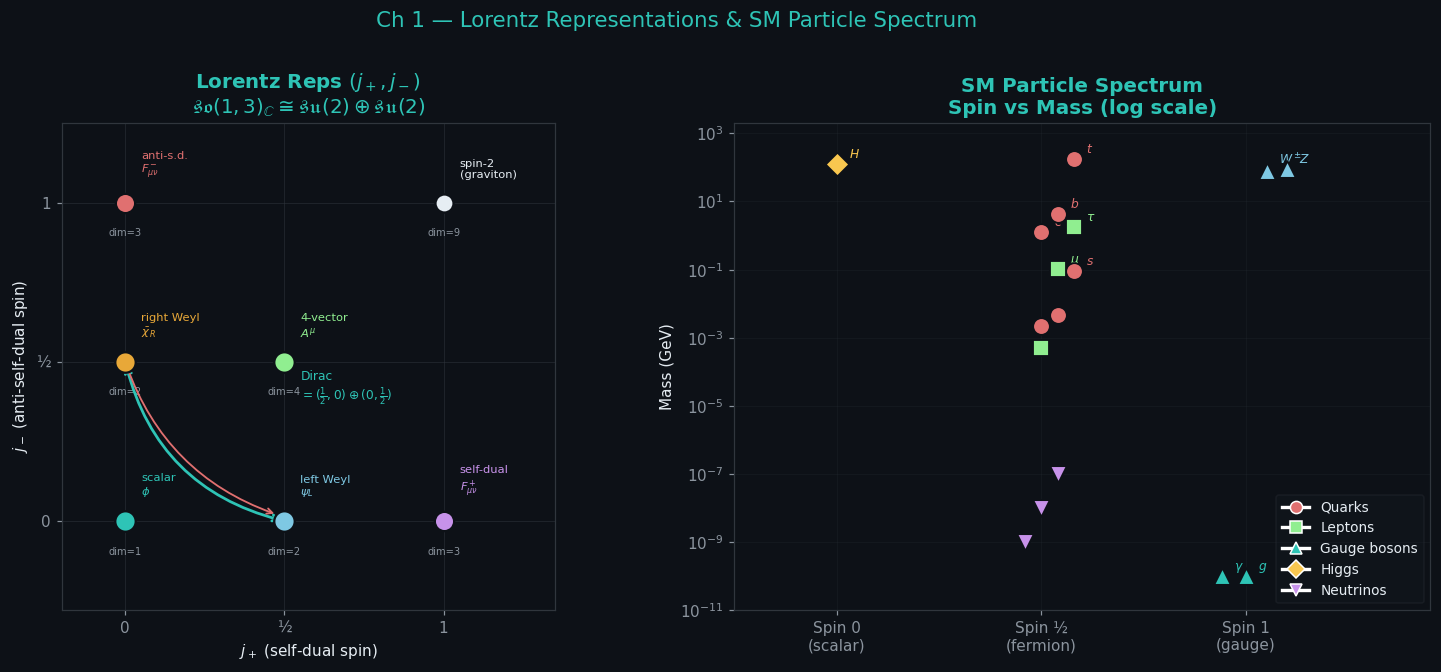

Saved: sm_vis1_symmetries.png


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Ch 1 — Lorentz Representations & SM Particle Spectrum',
             color=TEAL, fontsize=14, y=1.01)

# ── Left: (j+, j-) representation lattice ─────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')
ax.set_title(r'Lorentz Reps $(j_+, j_-)$' + '\n' +
             r'$\mathfrak{so}(1,3)_\mathbb{C} \cong \mathfrak{su}(2) \oplus \mathfrak{su}(2)$')

reps = [
    (0,   0,   r'$(0,0)$', 'scalar\n$\\phi$',        TEAL,   180),
    (0.5, 0,   r'$(\\frac{1}{2},0)$', 'left Weyl\n$\\psi_L$', BLUE,  180),
    (0,   0.5, r'$(0,\\frac{1}{2})$', 'right Weyl\n$\\bar\\chi_R$', ORAN, 180),
    (0.5, 0.5, r'$(\\frac{1}{2},\\frac{1}{2})$', '4-vector\n$A^\\mu$', GREEN, 180),
    (1,   0,   r'$(1,0)$',  'self-dual\n$F^+_{\\mu\\nu}$', PURP,  160),
    (0,   1,   r'$(0,1)$',  'anti-s.d.\n$F^-_{\\mu\\nu}$', RED,   160),
    (1,   1,   r'$(1,1)$',  'spin-2\n(graviton)',  TEXT,  140),
]

# Grid
for v in [0, 0.5, 1]:
    ax.axhline(v, color=EDGE, lw=0.7, alpha=0.5)
    ax.axvline(v, color=EDGE, lw=0.7, alpha=0.5)

for (jp, jm, jlbl, name, col, sz) in reps:
    dim = int((2*jp+1)*(2*jm+1))
    ax.scatter(jp, jm, s=sz, color=col, zorder=5, edgecolors=BG, lw=1.5)
    ax.text(jp + 0.05, jm + 0.07, name, fontsize=7.5, color=col, va='bottom')
    ax.text(jp, jm - 0.08, f'dim={dim}', fontsize=6.5, color=DIM,
            ha='center', va='top')

# Dirac = left + right arrow
ax.annotate('', xy=(0.5, 0.0), xytext=(0.0, 0.5),
            arrowprops=dict(arrowstyle='<->', color=TEAL, lw=1.8,
                            connectionstyle='arc3,rad=0.3'))
ax.text(0.55, 0.38, 'Dirac\n$=(\\frac{1}{2},0)\\oplus(0,\\frac{1}{2})$',
        fontsize=8, color=TEAL)

# P arrow
ax.annotate('P', xy=(0, 0.5), xytext=(0.5, 0),
            ha='center', color=RED, fontsize=9,
            arrowprops=dict(arrowstyle='<->', color=RED, lw=1.2,
                            connectionstyle='arc3,rad=-0.25'))

ax.set_xlim(-0.2, 1.35); ax.set_ylim(-0.28, 1.25)
ax.set_xlabel(r'$j_+$ (self-dual spin)')
ax.set_ylabel(r'$j_-$ (anti-self-dual spin)')
ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(['0', '½', '1'])
ax.set_yticks([0, 0.5, 1]); ax.set_yticklabels(['0', '½', '1'])
ax.grid(False)

# ── Right: SM particle spectrum ────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_title('SM Particle Spectrum\nSpin vs Mass (log scale)')

# (name, spin, mass_GeV, color, marker)
particles = [
    # Quarks
    ('$u$',  0.5, 2.2e-3,  RED,   'o'), ('$d$', 0.5, 4.7e-3,  RED,   'o'),
    ('$s$',  0.5, 93e-3,   RED,   'o'), ('$c$', 0.5, 1.27,    RED,   'o'),
    ('$b$',  0.5, 4.18,    RED,   'o'), ('$t$', 0.5, 173,     RED,   'o'),
    # Leptons
    ('$e$',  0.5, 511e-6,  GREEN, 's'), ('$\\mu$', 0.5, 0.1057, GREEN, 's'),
    ('$\\tau$', 0.5, 1.777, GREEN,'s'),
    # Gauge bosons
    ('$\\gamma$', 1, 1e-36, TEAL,  '^'), ('$g$',  1, 0,      TEAL,  '^'),
    ('$W^\\pm$',  1, 80.4,  BLUE,  '^'), ('$Z$',  1, 91.2,   BLUE,  '^'),
    # Higgs
    ('$H$',  0, 125.1, YELL, 'D'),
    # Neutrinos (upper bounds)
    ('$\\nu_e$',  0.5, 1e-9, PURP, 'v'),
    ('$\\nu_\\mu$',0.5, 1e-8, PURP, 'v'),
    ('$\\nu_\\tau$',0.5,1e-7, PURP, 'v'),
]

# Jitter spins for visibility
spin_jitter = {'$u$':0.0,'$d$':0.04,'$s$':0.08,'$c$':0.0,'$b$':0.04,'$t$':0.08,
               '$e$':0.0,'$\\mu$':0.04,'$\\tau$':0.08,
               '$\\gamma$':-0.06,'$g$':0.0,'$W^\\pm$':0.05,'$Z$':0.1,
               '$H$':0.0,'$\\nu_e$':-0.04,'$\\nu_\\mu$':0.0,'$\\nu_\\tau$':0.04}

for (name, spin, mass, col, mk) in particles:
    mass_plot = max(mass, 1e-10)
    jit = spin_jitter.get(name, 0)
    ax2.scatter(spin + jit, mass_plot, s=120, color=col, marker=mk,
                zorder=5, edgecolors=BG, lw=1.2)
    if mass > 0.05 or name in ['$\\gamma$','$g$']:
        ax2.text(spin + jit + 0.03, mass_plot * 1.5, name,
                 fontsize=8, color=col)

# Generation labels
for (gen, x) in [(r'Gen I', -0.12), (r'Gen II', -0.08), (r'Gen III', -0.04)]:
    pass  # simplify

# Legend
from matplotlib.lines import Line2D
handles = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=RED,  ms=8,label='Quarks'),
    Line2D([0],[0],marker='s',color='w',markerfacecolor=GREEN,ms=8,label='Leptons'),
    Line2D([0],[0],marker='^',color='w',markerfacecolor=TEAL, ms=8,label='Gauge bosons'),
    Line2D([0],[0],marker='D',color='w',markerfacecolor=YELL, ms=8,label='Higgs'),
    Line2D([0],[0],marker='v',color='w',markerfacecolor=PURP, ms=8,label='Neutrinos'),
]
ax2.legend(handles=handles, fontsize=9, labelcolor=TEXT, loc='lower right')
ax2.set_yscale('log')
ax2.set_ylim(1e-11, 2e3)
ax2.set_xlim(-0.25, 1.45)
ax2.set_xticks([0, 0.5, 1])
ax2.set_xticklabels(['Spin 0\n(scalar)', 'Spin ½\n(fermion)', 'Spin 1\n(gauge)'])
ax2.set_ylabel('Mass (GeV)')
ax2.grid(True, alpha=0.2, which='both')

plt.tight_layout()
plt.savefig('sm_vis1_symmetries.png', dpi=160, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: sm_vis1_symmetries.png')

---
## Visualization 2 · Mexican Hat Potential & Higgs Mechanism (Ch 2)

**Left**: 3D Mexican hat potential $V(\phi_1,\phi_2)=-\mu^2|\phi|^2+\lambda|\phi|^4$ — circle of minima at $|\phi|=v$  
**Right**: $W/Z/H$ mass vs VEV $v$ — showing the SM hierarchy at $v=246$ GeV

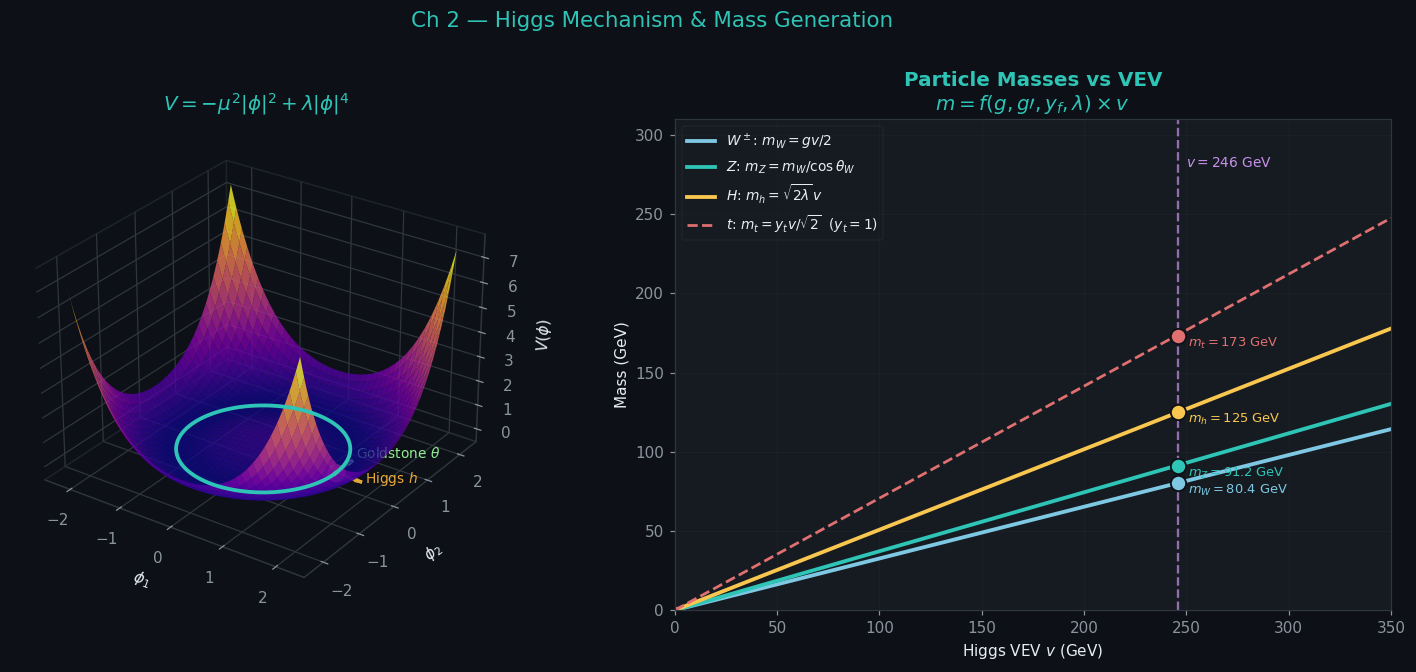

Saved: sm_vis2_higgs.png


In [3]:
fig = plt.figure(figsize=(14, 6), facecolor=BG)
fig.suptitle('Ch 2 — Higgs Mechanism & Mass Generation',
             color=TEAL, fontsize=14, y=1.01)

# ── Left: 3D Mexican hat ───────────────────────────────────────────────────
ax = fig.add_subplot(121, projection='3d', facecolor=BG)
ax.set_facecolor(BG)

mu2, lam = 1.0, 0.5
v = np.sqrt(mu2 / lam)
phi_r = np.linspace(-2.2, 2.2, 120)
P1, P2 = np.meshgrid(phi_r, phi_r)
R2 = P1**2 + P2**2
V  = -0.5*mu2*R2 + 0.25*lam*R2**2
V -= V.min()

surf = ax.plot_surface(P1, P2, V, cmap='plasma', alpha=0.80,
                       linewidth=0, antialiased=True)

# Circle of minima
theta_c = np.linspace(0, 2*np.pi, 200)
ax.plot(v*np.cos(theta_c), v*np.sin(theta_c), np.zeros(200),
        color=TEAL, lw=2.5, zorder=6)

# Chosen vacuum
ax.scatter([v], [0], [0], color=YELL, s=120, zorder=7)

# Radial (Higgs) and angular (Goldstone) directions
ax.quiver(v, 0, 0, 0.5, 0, 0.0, color=ORAN, lw=2, arrow_length_ratio=0.3)
ax.text(v+0.55, 0, 0, r'Higgs $h$', color=ORAN, fontsize=9)
ax.quiver(v, 0, 0, 0.0, 0.5, 0.0, color=GREEN, lw=2, arrow_length_ratio=0.3)
ax.text(v, 0.6, 0, r'Goldstone $\theta$', color=GREEN, fontsize=9)

ax.set_xlabel(r'$\phi_1$', color=TEXT)
ax.set_ylabel(r'$\phi_2$', color=TEXT)
ax.set_zlabel(r'$V(\phi)$', color=TEXT)
ax.set_title(r'$V = -\mu^2|\phi|^2 + \lambda|\phi|^4$', color=TEAL)
ax.tick_params(colors=DIM)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor(EDGE)
ax.yaxis.pane.set_edgecolor(EDGE)
ax.zaxis.pane.set_edgecolor(EDGE)
ax.view_init(elev=28, azim=-55)

# ── Right: W/Z/H masses vs VEV ─────────────────────────────────────────────
ax2 = fig.add_subplot(122)
ax2.set_facecolor(SURF)

g  = 0.653   # SU(2) coupling
gp = 0.357   # U(1) coupling
lam_h = 0.129  # Higgs self-coupling

v_range = np.linspace(0, 350, 300)  # GeV

mW = g * v_range / 2
mZ = np.sqrt(g**2 + gp**2) * v_range / 2
mH = np.sqrt(2 * lam_h) * v_range
mt = v_range / np.sqrt(2)  # top Yukawa ~ 1

ax2.plot(v_range, mW, color=BLUE,  lw=2.5, label=r'$W^\pm$: $m_W = gv/2$')
ax2.plot(v_range, mZ, color=TEAL,  lw=2.5, label=r'$Z$: $m_Z = m_W/\cos\theta_W$')
ax2.plot(v_range, mH, color=YELL,  lw=2.5, label=r'$H$: $m_h = \sqrt{2\lambda}\,v$')
ax2.plot(v_range, mt, color=RED,   lw=1.8, ls='--',
         label=r'$t$: $m_t = y_t v/\sqrt{2}$  ($y_t=1$)')

# SM point v=246 GeV
v_SM = 246.0
for (m, col, lbl) in [(80.4, BLUE, r'$m_W=80.4$'),
                       (91.2, TEAL, r'$m_Z=91.2$'),
                       (125.1,YELL, r'$m_h=125$'),
                       (173.3,RED,  r'$m_t=173$')]:
    ax2.scatter([v_SM], [m], s=100, color=col, zorder=5,
                edgecolors=BG, lw=1.2)
    ax2.text(v_SM + 5, m - 7, lbl + ' GeV', color=col, fontsize=8.5)

ax2.axvline(v_SM, color=PURP, lw=1.5, ls='--', alpha=0.7)
ax2.text(v_SM + 4, 280, r'$v = 246$ GeV', color=PURP, fontsize=9)

ax2.set_xlabel(r'Higgs VEV $v$ (GeV)')
ax2.set_ylabel('Mass (GeV)')
ax2.set_title(r'Particle Masses vs VEV' + '\n'
              r'$m = f(g,g\prime,y_f,\lambda) \times v$')
ax2.legend(fontsize=9, labelcolor=TEXT, loc='upper left')
ax2.set_xlim(0, 350); ax2.set_ylim(0, 310)
ax2.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('sm_vis2_higgs.png', dpi=160, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: sm_vis2_higgs.png')

---
## Visualization 3 · Running Coupling & QCD Phase Structure (Ch 3)

**Left**: $\alpha_s(\mu)$ vs energy scale with experimental data points — asymptotic freedom  
**Right**: QCD phase diagram in the $(T, \mu_B)$ plane — hadron gas, QGP, colour superconductor

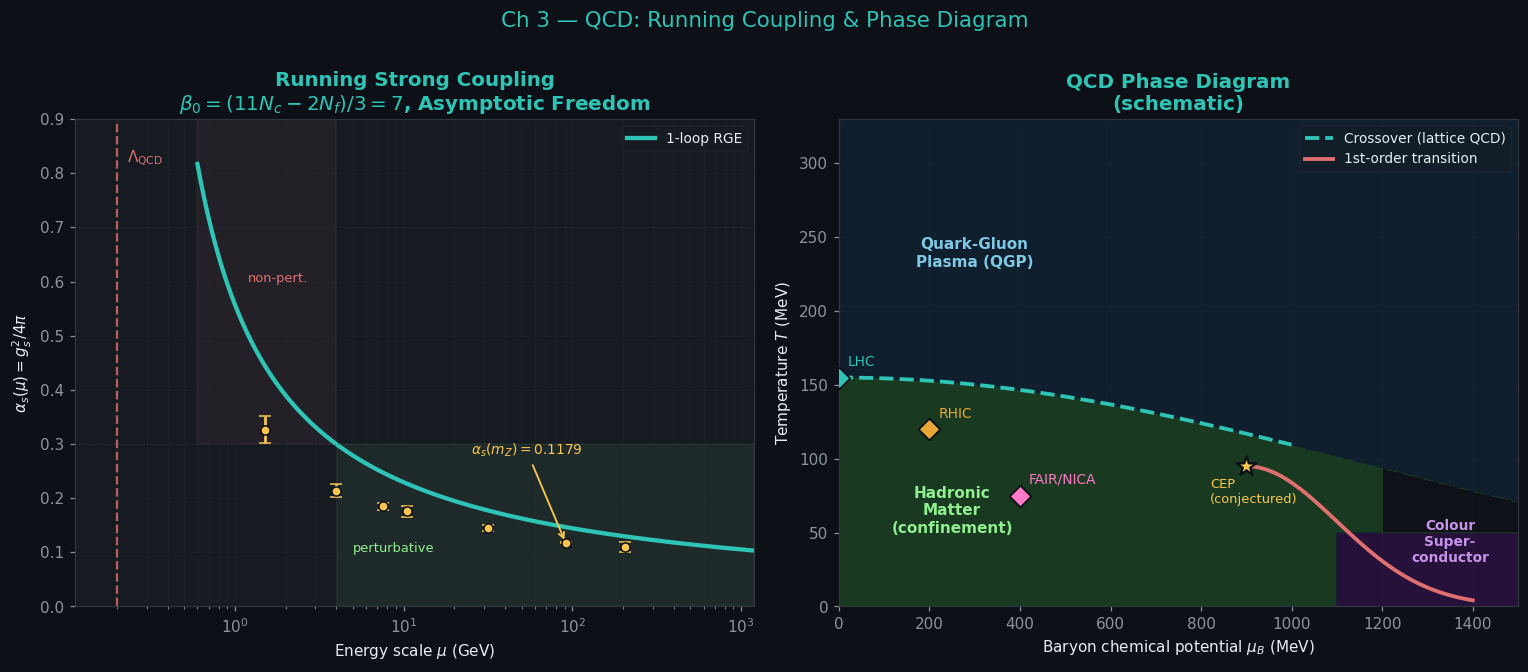

Saved: sm_vis3_qcd.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Ch 3 — QCD: Running Coupling & Phase Diagram',
             color=TEAL, fontsize=14, y=1.01)

# ── Left: alpha_s running ──────────────────────────────────────────────────
ax = axes[0]

Nc, Nf = 3, 6
b0 = (11*Nc - 2*Nf) / 3  # = 7
L_QCD = 0.2  # GeV

mu = np.logspace(np.log10(0.6), np.log10(1200), 500)
mask = mu > L_QCD * 1.4
alpha_s = np.where(mask,
    2*np.pi / (b0 * np.log(np.where(mask, mu/L_QCD, 1))),
    np.nan)
alpha_s = np.where(alpha_s < 0.9, alpha_s, np.nan)

ax.semilogx(mu, alpha_s, color=TEAL, lw=2.8, label='1-loop RGE')

# Experimental data
data_exp = [
    (1.5,   0.326, 0.025), (4.0,   0.214, 0.012),
    (7.5,   0.185, 0.007), (10.5,  0.176, 0.010),
    (31.6,  0.145, 0.005), (91.2,  0.1179,0.0010),
    (206.0, 0.110, 0.010),
]
for (mu_e, a_e, err) in data_exp:
    ax.errorbar(mu_e, a_e, yerr=err, fmt='o', color=YELL,
                ms=6, capsize=4, elinewidth=1.8,
                markeredgecolor=BG, markeredgewidth=1)

# Annotations
ax.axvline(L_QCD, color=RED, lw=1.5, ls='--', alpha=0.8)
ax.text(L_QCD*1.15, 0.82, r'$\Lambda_{\rm QCD}$', color=RED, fontsize=10)
ax.axhline(0.3, color=EDGE, lw=0.8, ls=':', alpha=0.5)
ax.fill_between(mu, 0, 0.3,
                where=(~np.isnan(alpha_s)) & (alpha_s < 0.3),
                color=GREEN, alpha=0.07)
ax.fill_between(mu, 0.3, 1.0,
                where=(~np.isnan(alpha_s)) & (alpha_s >= 0.3),
                color=RED, alpha=0.07)
ax.text(5.0,  0.10, 'perturbative', color=GREEN, fontsize=8.5)
ax.text(1.2, 0.60, 'non-pert.', color=RED,   fontsize=8.5)

ax.annotate(r'$\alpha_s(m_Z)=0.1179$', xy=(91.2, 0.1179),
            xytext=(25, 0.28), color=YELL, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=YELL, lw=1.2))

ax.set_xlabel(r'Energy scale $\mu$ (GeV)')
ax.set_ylabel(r'$\alpha_s(\mu) = g_s^2/4\pi$')
ax.set_title(r'Running Strong Coupling' + '\n'
             r'$\beta_0 = (11N_c-2N_f)/3 = 7$, Asymptotic Freedom')
ax.legend(fontsize=9, labelcolor=TEXT)
ax.set_xlim(0.0, 1200); ax.set_ylim(0, 0.90)
ax.grid(True, alpha=0.2, which='both')

# ── Right: QCD phase diagram ───────────────────────────────────────────────
ax2 = axes[1]

T   = np.linspace(0, 350, 400)   # MeV
muB = np.linspace(0, 1500, 400)  # MeV
T_g, M_g = np.meshgrid(T, muB)

# Phase boundaries (schematic)
# Crossover line (lattice QCD): T_c ~ 155 MeV at mu_B=0
T_cross = 155 * np.exp(-0.5*(M_g/1200)**2)
# First-order line (schematic)
T_1st   = 155 * np.exp(-0.5*(M_g/800)**2) * (M_g > 800)
# CEP at ~ (mu_B~900, T~95)

# Colour the phases
hadron   = (T_g < T_cross) & (M_g < 1200)
qgp      = (T_g >= T_cross)
csc      = (T_g < 50) & (M_g > 1100)

phase_map = np.zeros(T_g.shape)
phase_map[hadron]  = 1
phase_map[qgp]     = 2
phase_map[csc]     = 3

cmap_phase = LinearSegmentedColormap.from_list(
    'phases', [BG, '#1a3a2a', '#1a2a3a', '#2a1a3a'], N=4)
ax2.contourf(muB, T, phase_map.T, levels=[-0.5,0.5,1.5,2.5,3.5],
             colors=[BG, '#1a4020', '#102030', '#2a1040'], alpha=0.85)

# Crossover line
mu_arr = np.linspace(0, 1000, 200)
T_cline = 155 * np.exp(-0.5*(mu_arr/1200)**2)
ax2.plot(mu_arr, T_cline, color=TEAL, lw=2.5, ls='--',
         label='Crossover (lattice QCD)')

# First-order line
mu_fo = np.linspace(900, 1400, 100)
T_fo  = 95 * np.exp(-2.0*((mu_fo-900)/400)**2)
ax2.plot(mu_fo, T_fo, color=RED, lw=2.5, label='1st-order transition')

# Critical end point
ax2.scatter([900], [95], s=180, color=YELL, zorder=6,
            edgecolors=BG, lw=1.5, marker='*')
ax2.text(820, 70, 'CEP\n(conjectured)', color=YELL, fontsize=8.5)

# Phase labels
ax2.text(250, 50,  'Hadronic\nMatter\n(confinement)', ha='center',
         color=GREEN, fontsize=10, fontweight='bold')
ax2.text(300, 230, 'Quark-Gluon\nPlasma (QGP)',       ha='center',
         color=BLUE, fontsize=10, fontweight='bold')
ax2.text(1350, 30, 'Colour\nSuper-\nconductor', ha='center',
         color=PURP, fontsize=9, fontweight='bold')

# Experimental points
exp_pts = [
    (0,   155, 'LHC', TEAL),
    (200, 120, 'RHIC', ORAN),
    (400, 75,  'FAIR/NICA', PINK),
]
for (mu_e, T_e, lbl, col) in exp_pts:
    ax2.scatter([mu_e], [T_e], s=100, color=col, zorder=7,
                edgecolors=BG, lw=1.2, marker='D')
    ax2.text(mu_e+20, T_e+8, lbl, color=col, fontsize=9)

ax2.legend(fontsize=9, labelcolor=TEXT, loc='upper right')
ax2.set_xlabel(r'Baryon chemical potential $\mu_B$ (MeV)')
ax2.set_ylabel(r'Temperature $T$ (MeV)')
ax2.set_title('QCD Phase Diagram\n(schematic)')
ax2.set_xlim(0, 1500); ax2.set_ylim(0, 330)
ax2.grid(True, alpha=0.15)

plt.tight_layout()
plt.savefig('sm_vis3_qcd.png', dpi=160, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: sm_vis3_qcd.png')

---
## Visualization 4 · Triangle Anomaly & $\pi^0\to\gamma\gamma$ (Ch 4)

**Left**: $\Gamma(\pi^0\to\gamma\gamma)$ vs $N_c$ — anomaly prediction, experimental value, $N_c=3$ confirmation  
**Right**: Anomaly cancellation in the SM — $[U(1)_Y]^3$ contributions per field visualised as bar chart

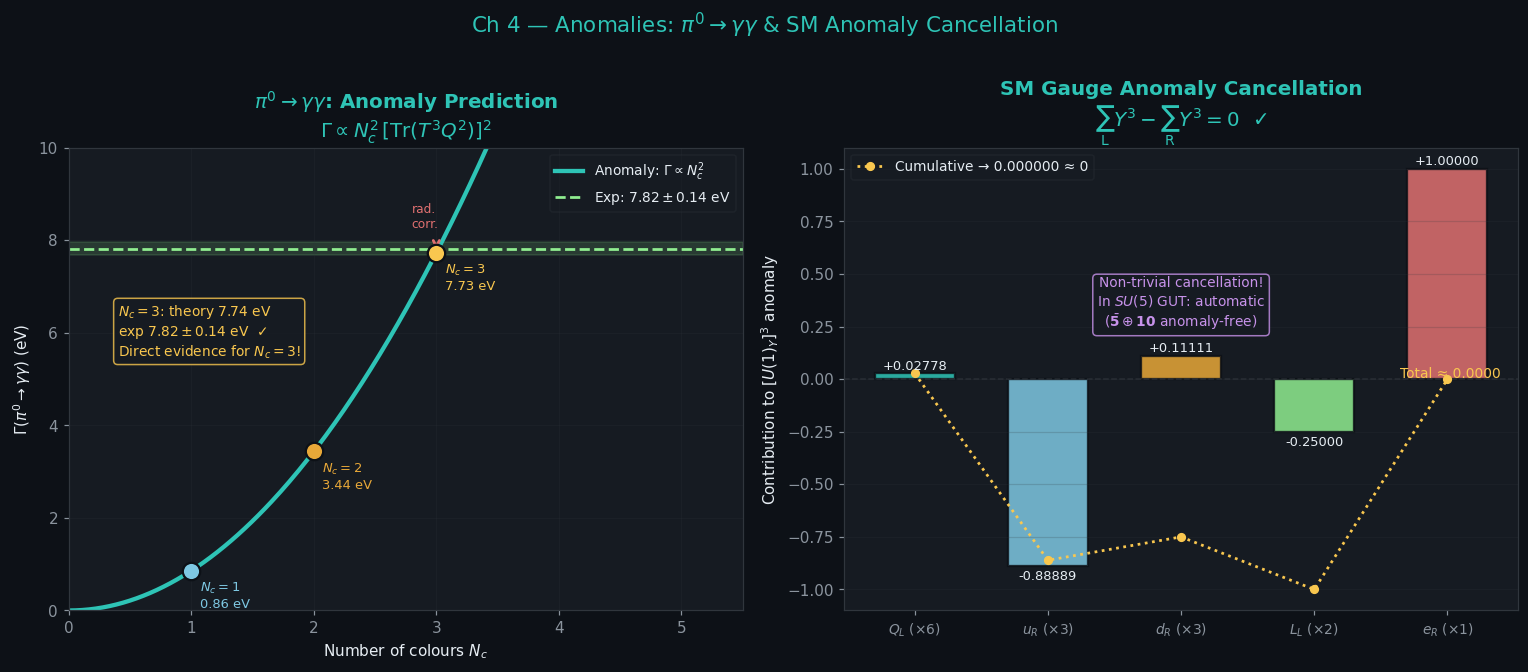

Saved: sm_vis4_anomaly.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Ch 4 — Anomalies: $\\pi^0\\to\\gamma\\gamma$ & SM Anomaly Cancellation',
             color=TEAL, fontsize=14, y=1.01)

# ── Left: Gamma(pi0->gamgam) vs Nc ───────────────────────────────────────
ax = axes[0]

alpha_em = 1/137.036
m_pi     = 0.135    # GeV
f_pi     = 0.0924   # GeV
prefac   = alpha_em**2 * m_pi**3 / (64 * np.pi**3 * f_pi**2) * 1e9  # eV

Nc_c = np.linspace(0, 5.5, 300)
Gamma_Nc = prefac * (Nc_c / 3)**2

ax.plot(Nc_c, Gamma_Nc, color=TEAL, lw=2.8, label=r'Anomaly: $\Gamma\propto N_c^2$')

# Integer Nc points
for nc, col, lbl in [(1,BLUE,r'$N_c=1$'),(2,ORAN,r'$N_c=2$'),
                      (3,YELL,r'$N_c=3$')]: #,(4,PURP,r'$N_c=4$'),(5,RED,r'$N_c=5$')]:
    gv = prefac*(nc/3)**2
    ax.scatter([nc],[gv], s=130, color=col, zorder=5,
               edgecolors=BG, lw=1.5)
    ax.text(nc+0.07, gv-0.8, f'{lbl}\n{gv:.2f} eV', color=col, fontsize=8.5)

# Experimental value
G_exp, G_err = 7.82, 0.14
ax.axhline(G_exp, color=GREEN, lw=1.8, ls='--',
           label=fr'Exp: $7.82\pm0.14$ eV')
ax.fill_between(Nc_c, G_exp-G_err, G_exp+G_err,
                color=GREEN, alpha=0.15)

# Nc=3 match annotation
G_3 = prefac*(3/3)**2
ax.annotate('',xy=(3,G_exp), xytext=(3,G_3),
            arrowprops=dict(arrowstyle='<->',color=RED,lw=1.8))
ax.text(2.8, (G_exp+G_3)/2 +0.5, 'rad.\ncorr.', color=RED, fontsize=8)

# Shading
ax.text(0.4, 5.5,
        r'$N_c=3$: theory $7.74$ eV' + '\n'
        r'exp $7.82\pm0.14$ eV  ✓' + '\n'
        'Direct evidence for $N_c=3$!',
        color=YELL, fontsize=9,
        bbox=dict(boxstyle='round', fc=SURF, ec=YELL, alpha=0.8))

ax.set_xlabel(r'Number of colours $N_c$')
ax.set_ylabel(r'$\Gamma(\pi^0\to\gamma\gamma)$ (eV)')
ax.set_title(r'$\pi^0\to\gamma\gamma$: Anomaly Prediction' + '\n'
             r'$\Gamma\propto N_c^2\,[\mathrm{Tr}(T^3Q^2)]^2$')
ax.legend(fontsize=9, labelcolor=TEXT)
ax.set_xlim(0, 5.5); ax.set_ylim(0, 10)
ax.grid(True, alpha=0.2)

# ── Right: SM anomaly cancellation bar chart ──────────────────────────────
ax2 = axes[1]

fields = [
    (r'$Q_L$ (×6)',  +6*(1/6)**3,  TEAL),
    (r'$u_R$ (×3)',  -3*(2/3)**3,  BLUE),
    (r'$d_R$ (×3)',  -3*(-1/3)**3, ORAN),
    (r'$L_L$ (×2)',  +2*(-1/2)**3, GREEN),
    (r'$e_R$ (×1)',  -1*(-1)**3,   RED),
]
labels = [f[0] for f in fields]
values = [f[1] for f in fields]
cols   = [f[2] for f in fields]
x_pos  = np.arange(len(fields))

bars = ax2.bar(x_pos, values, color=cols, alpha=0.85,
               edgecolor=BG, linewidth=1.5, width=0.6)

# Value labels
for bar, val in zip(bars, values):
    yp = bar.get_height() + 0.003 if val >= 0 else bar.get_height() - 0.018
    ax2.text(bar.get_x()+bar.get_width()/2, yp,
             f'{val:+.5f}', ha='center',
             va='bottom' if val >= 0 else 'top',
             color=TEXT, fontsize=8.5)

ax2.axhline(0, color=EDGE, lw=1.0, ls='--', alpha=0.7)

# Cumulative sum
cumsum = np.cumsum(values)
ax2.plot(x_pos, cumsum, color=YELL, lw=1.8, ls=':', marker='o',
         ms=5, label=f'Cumulative → {sum(values):.6f} ≈ 0')

total = sum(values)
ax2.text(4.4, 0.006, f'Total ≈ {total:.4f}', color=YELL, fontsize=9,
         ha='right')

# Result box
ax2.text(2.0, 0.25,
         r'Non-trivial cancellation!' + '\n'
         'In $SU(5)$ GUT: automatic\n'
         r'($\bar{\mathbf{5}}\oplus\mathbf{10}$ anomaly-free)',
         ha='center', color=PURP, fontsize=9,
         bbox=dict(boxstyle='round', fc=SURF, ec=PURP, alpha=0.8))

ax2.set_xticks(x_pos)
ax2.set_xticklabels(labels, fontsize=9)
ax2.set_ylabel(r'Contribution to $[U(1)_Y]^3$ anomaly')
ax2.set_title(r'SM Gauge Anomaly Cancellation' + '\n'
              r'$\sum_{\rm L}Y^3 - \sum_{\rm R}Y^3 = 0$  $\checkmark$')
ax2.legend(fontsize=9, labelcolor=TEXT)
ax2.grid(True, alpha=0.2, axis='y')

plt.tight_layout()
plt.savefig('sm_vis4_anomaly.png', dpi=160, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: sm_vis4_anomaly.png')

---
## Visualization 5 · $Z$ Partial Widths & EW Precision (Ch 5)

**Left**: $Z$ partial width breakdown — theory vs experiment, $N_\nu=3$ from invisible width  
**Right**: $\sin^2\theta_W$ measurements from different observables — global EW fit consistency

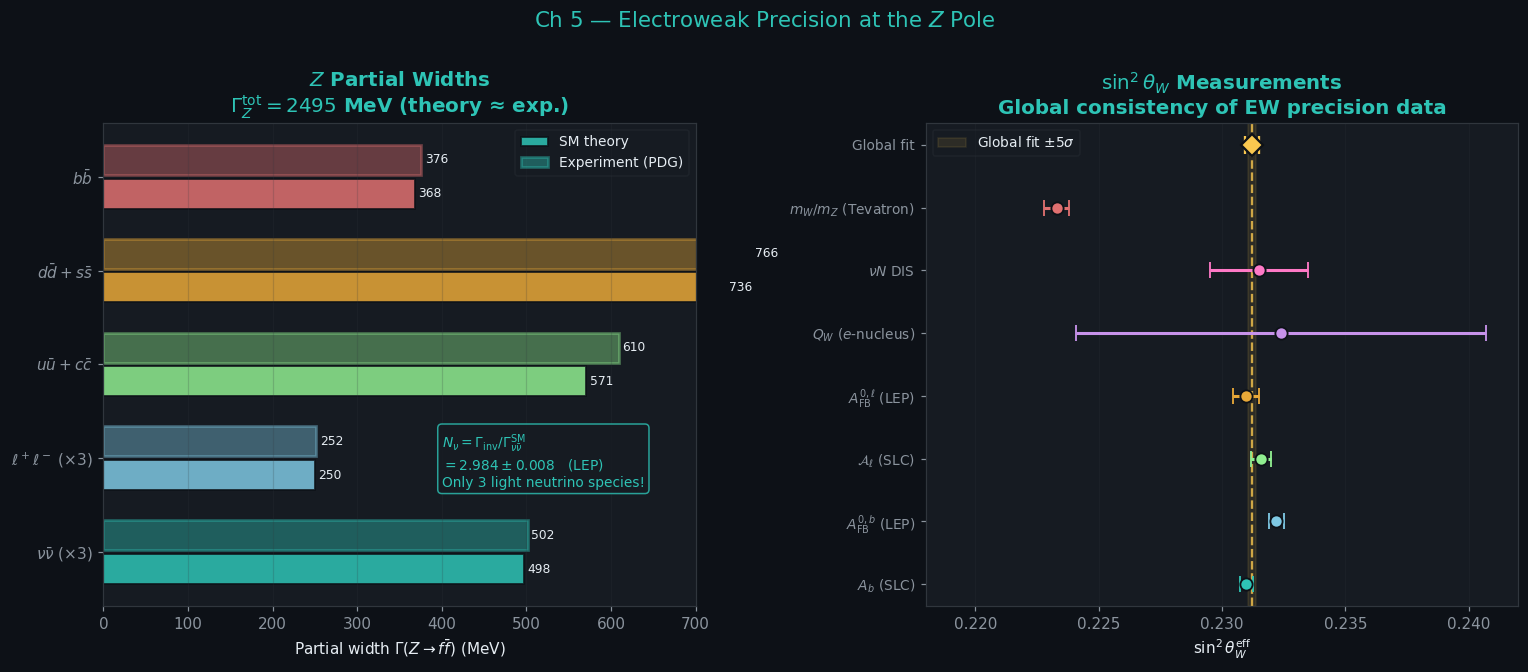

Saved: sm_vis5_electroweak.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Ch 5 — Electroweak Precision at the $Z$ Pole',
             color=TEAL, fontsize=14, y=1.01)

sw2 = 0.2312
GF  = 1.1664e-5
mZ  = 91.1876
prefac_w = GF * mZ**3 / (6 * np.sqrt(2) * np.pi) * 1000  # MeV

fermions = [
    (r'$\nu\bar\nu$ (×3)', 3, +0.5, 0,    1, TEAL),
    (r'$\ell^+\ell^-$ (×3)', 3, -0.5+2*sw2, -0.5, 1, BLUE),
    (r'$u\bar u+c\bar c$',   2, +0.5-4/3*sw2, +0.5, 3, GREEN),
    (r'$d\bar d+s\bar s$',   2, -0.5+2/3*sw2, -0.5, 3, ORAN),
    (r'$b\bar b$',           1, -0.5+2/3*sw2, -0.5, 3, RED),
]

# ── Left: partial widths ───────────────────────────────────────────────────
ax = axes[0]

widths_th, widths_exp, labels_w, cols_w = [], [], [], []
exp_vals = [501.7, 3*83.9, 2*304.8, 2*382.8, 375.9]  # MeV (PDG)

for i, (lbl, mult, gV, gA, Nc, col) in enumerate(fermions):
    if i == 0:  # neutrinos: gV=gA=0.5
        w_th = 3 * prefac_w * 1 * (0.25 + 0.25)
    else:
        w_th = mult * prefac_w * Nc * (gV**2 + gA**2)
    widths_th.append(w_th)
    widths_exp.append(exp_vals[i])
    labels_w.append(lbl)
    cols_w.append(col)

y_pos = np.arange(len(fermions))
ax.barh(y_pos - 0.18, widths_th,  0.32, color=cols_w, alpha=0.85,
        edgecolor=BG, lw=1.2, label='SM theory')
ax.barh(y_pos + 0.18, widths_exp, 0.32, color=cols_w, alpha=0.40,
        edgecolor=[c for c in cols_w], lw=1.8, label='Experiment (PDG)')

# Value labels
for i,(th,ex) in enumerate(zip(widths_th,widths_exp)):
    ax.text(th+4,  y_pos[i]-0.18, f'{th:.0f}', va='center',
            color=TEXT, fontsize=8)
    ax.text(ex+4, y_pos[i]+0.18, f'{ex:.0f}', va='center',
            color=TEXT, fontsize=8)

# N_nu annotation
ax.text(400, 0.7,
        r'$N_\nu = \Gamma_{\rm inv}/\Gamma_{\nu\bar\nu}^{\rm SM}$' + '\n'
        r'$= 2.984\pm0.008$   (LEP)' + '\n'
        'Only 3 light neutrino species!',
        color=TEAL, fontsize=9,
        bbox=dict(boxstyle='round', fc=SURF, ec=TEAL, alpha=0.8))

ax.set_yticks(y_pos)
ax.set_yticklabels(labels_w, fontsize=10)
ax.set_xlabel(r'Partial width $\Gamma(Z\to f\bar f)$ (MeV)')
ax.set_title(r'$Z$ Partial Widths' + '\n'
             r'$\Gamma_Z^{\rm tot}=2495$ MeV (theory ≈ exp.)')
ax.legend(fontsize=9, labelcolor=TEXT)
ax.set_xlim(0, 700)
ax.grid(True, alpha=0.2, axis='x')

# ── Right: sin^2(theta_W) measurements ────────────────────────────────────
ax2 = axes[1]

sw2_meas = [
    (r'$A_b$ (SLC)',              0.23098, 0.00026, TEAL),
    (r"$A_{\rm FB}^{0,b}$ (LEP)", 0.23221, 0.00029, BLUE),
    (r"$\mathcal{A}_\ell$ (SLC)", 0.23159, 0.00041, GREEN),
    (r"$A_{\rm FB}^{0,\ell}$ (LEP)",0.23099,0.00053,ORAN),
    (r'$Q_W$ ($e$-nucleus)',       0.2324,  0.0083,  PURP),
    (r'$\nu N$ DIS',              0.2315,  0.0020,  PINK),
    (r'$m_W/m_Z$ (Tevatron)',     0.2233,  0.0005,  RED),
    (r'Global fit',               0.23122, 0.00003, YELL),
]

y_m = np.arange(len(sw2_meas))
global_val, global_err = 0.23122, 0.00003

# Global fit band
ax2.axvspan(global_val - global_err*5, global_val + global_err*5,
            color=YELL, alpha=0.10, label='Global fit $\\pm5\\sigma$')
ax2.axvline(global_val, color=YELL, lw=1.5, ls='--', alpha=0.8)

for i, (lbl, val, err, col) in enumerate(sw2_meas[:-1]):
    ax2.errorbar(val, i, xerr=err, fmt='o', color=col,
                 ms=8, capsize=5, elinewidth=2.0,
                 markeredgecolor=BG, markeredgewidth=1.2, zorder=5)

ax2.errorbar(global_val, len(sw2_meas)-1, xerr=global_err*10,
             fmt='D', color=YELL, ms=10, capsize=6, elinewidth=2.5,
             markeredgecolor=BG, markeredgewidth=1.5, zorder=6)

ax2.set_yticks(y_m)
ax2.set_yticklabels([s[0] for s in sw2_meas], fontsize=9)
ax2.set_xlabel(r'$\sin^2\theta_W^{\rm eff}$')
ax2.set_title(r'$\sin^2\theta_W$ Measurements' + '\n'
              'Global consistency of EW precision data')
ax2.legend(fontsize=9, labelcolor=TEXT, loc='upper left')
ax2.set_xlim(0.218, 0.242)
ax2.grid(True, alpha=0.2, axis='x')

plt.tight_layout()
plt.savefig('sm_vis5_electroweak.png', dpi=160, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: sm_vis5_electroweak.png')

---
## Visualization 6 · CKM Unitarity Triangle & $B$-factory CP Asymmetry (Ch 6)

**Left**: Unitarity triangle in the $(\bar\rho, \bar\eta)$ plane with experimental constraints  
**Right**: Time-dependent CP asymmetry $\mathcal{A}_{CP}(t)$ in $B^0\to J/\psi K_S$

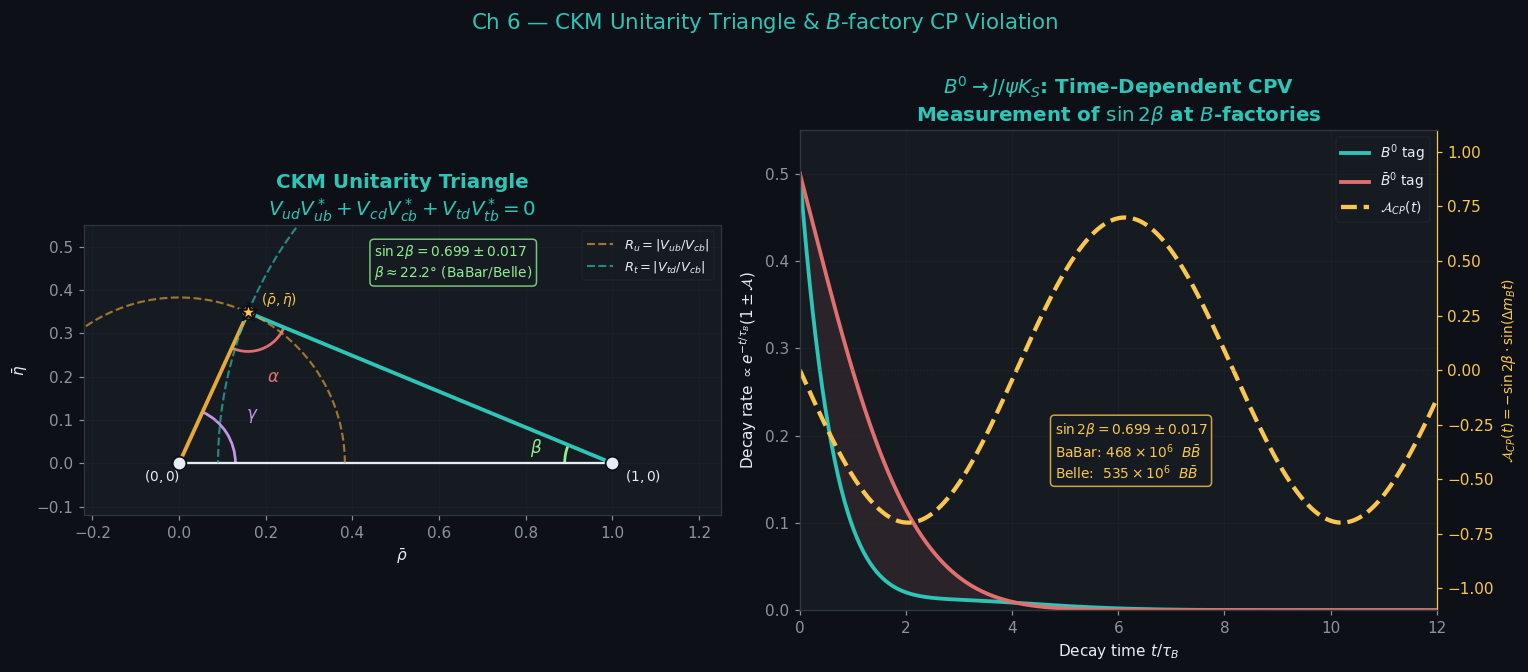

Saved: sm_vis6_flavour.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Ch 6 — CKM Unitarity Triangle & $B$-factory CP Violation',
             color=TEAL, fontsize=14, y=1.01)

lam = 0.22500; A = 0.826; rhobar = 0.159; etabar = 0.348

# ── Left: unitarity triangle ───────────────────────────────────────────────
ax = axes[0]

A_v = np.array([0.0,    0.0])
B_v = np.array([1.0,    0.0])
C_v = np.array([rhobar, etabar])

for (P,Q,col,lw) in [(A_v,B_v,TEXT,1.5),(B_v,C_v,TEAL,2.5),(C_v,A_v,ORAN,2.5)]:
    ax.plot([P[0],Q[0]],[P[1],Q[1]], color=col, lw=lw)

# Vertices
for (pt,lbl,col,dx,dy) in [
    (A_v, r'$(0,0)$',       TEXT, -0.08, -0.04),
    (B_v, r'$(1,0)$',       TEXT,  0.03, -0.04),
    (C_v, r'$(\bar\rho,\bar\eta)$', YELL, 0.03, 0.02)]:
    ax.scatter(*pt, s=80, color=col, zorder=6, edgecolors=BG, lw=1.2)
    ax.text(pt[0]+dx, pt[1]+dy, lbl, color=col, fontsize=9)

# Constraint circles
R_u = np.linalg.norm(C_v)
R_t = np.linalg.norm(C_v - B_v)
for (cx,cy,R,col,lbl) in [(0,0,R_u,ORAN,r'$R_u = |V_{ub}/V_{cb}|$'),
                            (1,0,R_t,TEAL,r'$R_t = |V_{td}/V_{cb}|$')]:
    theta_arr = np.linspace(0, np.pi, 200)
    ax.plot(cx+R*np.cos(theta_arr), cy+R*np.sin(theta_arr),
            color=col, lw=1.4, ls='--', alpha=0.65, label=lbl)

# Angles
def angle_arc(ax, vx, vy, p1, p2, r, lbl, col):
    v1=(p1-np.array([vx,vy])); v1/=np.linalg.norm(v1)
    v2=(p2-np.array([vx,vy])); v2/=np.linalg.norm(v2)
    a1=np.degrees(np.arctan2(v1[1],v1[0]))
    a2=np.degrees(np.arctan2(v2[1],v2[0]))
    if a2<a1: a1,a2=a2,a1
    arc=Arc((vx,vy),2*r,2*r,angle=0,theta1=a1,theta2=a2,color=col,lw=1.8)
    ax.add_patch(arc)
    mid=np.radians((a1+a2)/2)
    ax.text(vx+(r+0.07)*np.cos(mid),vy+(r+0.07)*np.sin(mid),
            lbl,color=col,fontsize=11,ha='center',va='center')

angle_arc(ax, A_v[0],A_v[1], B_v,C_v, 0.13, r'$\gamma$', PURP)
angle_arc(ax, B_v[0],B_v[1], A_v,C_v, 0.11, r'$\beta$',  GREEN)
angle_arc(ax, C_v[0],C_v[1], A_v,B_v, 0.09, r'$\alpha$', RED)

# sin2beta annotation
ax.text(0.45, 0.43,
        r'$\sin 2\beta=0.699\pm0.017$' + '\n'
        r'$\beta\approx22.2°$ (BaBar/Belle)',
        color=GREEN, fontsize=9,
        bbox=dict(boxstyle='round', fc=SURF, ec=GREEN, alpha=0.8))

ax.scatter(*C_v, s=150, color=YELL, marker='*', zorder=7,
           edgecolors=BG, lw=1.5)
ax.set_aspect('equal')
ax.set_xlim(-0.22, 1.25); ax.set_ylim(-0.12, 0.55)
ax.set_xlabel(r'$\bar\rho$'); ax.set_ylabel(r'$\bar\eta$')
ax.set_title('CKM Unitarity Triangle\n'
             r'$V_{ud}V_{ub}^*+V_{cd}V_{cb}^*+V_{td}V_{tb}^*=0$')
ax.legend(fontsize=8.5, labelcolor=TEXT, loc='upper right')
ax.grid(True, alpha=0.15)

# ── Right: B0 time-dependent CP asymmetry ─────────────────────────────────
ax2 = axes[1]

sin2b   = 0.699
tau_B   = 1.519e-12    # s
DmB     = 0.5065e12    # s^-1
t_norm  = np.linspace(0, 12, 600)

env     = np.exp(-t_norm)
A_cp_t  = -sin2b * np.sin(DmB * tau_B * t_norm)

rate_B0    = 0.5*env*(1 - sin2b*np.sin(DmB*tau_B*t_norm))
rate_B0bar = 0.5*env*(1 + sin2b*np.sin(DmB*tau_B*t_norm))

ax2_r = ax2.twinx()
ax2_r.set_facecolor(SURF)

ax2.plot(t_norm, rate_B0,    color=TEAL,  lw=2.5, label=r'$B^0$ tag')
ax2.plot(t_norm, rate_B0bar, color=RED,   lw=2.5, label=r'$\bar B^0$ tag')
ax2.fill_between(t_norm, rate_B0, rate_B0bar,
                 where=rate_B0>rate_B0bar, color=TEAL, alpha=0.10)
ax2.fill_between(t_norm, rate_B0, rate_B0bar,
                 where=rate_B0<rate_B0bar, color=RED,  alpha=0.10)

ax2_r.plot(t_norm, A_cp_t, color=YELL, lw=2.8, ls='--',
           label=r'$\mathcal{A}_{CP}(t)$')
ax2_r.axhline(0, color=EDGE, lw=0.8, ls=':', alpha=0.5)
ax2_r.set_ylabel(r'$\mathcal{A}_{CP}(t)=-\sin2\beta\cdot\sin(\Delta m_B t)$',
                 color=YELL, fontsize=9)
ax2_r.tick_params(colors=YELL)
ax2_r.spines['right'].set_color(YELL)
ax2_r.set_ylim(-1.1, 1.1)

ax2.text(4.8, 0.15,
         r'$\sin2\beta=0.699\pm0.017$' + '\n'
         r'BaBar: $468\times10^6$  $B\bar B$' + '\n'
         r'Belle:  $535\times10^6$  $B\bar B$',
         color=YELL, fontsize=9,
         bbox=dict(boxstyle='round', fc=SURF, ec=YELL, alpha=0.8))

lns1,lbs1 = ax2.get_legend_handles_labels()
lns2,lbs2 = ax2_r.get_legend_handles_labels()
ax2.legend(lns1+lns2, lbs1+lbs2, fontsize=9, labelcolor=TEXT, loc='upper right')
ax2.set_xlabel(r'Decay time $t/\tau_B$')
ax2.set_ylabel(r'Decay rate $\propto e^{-t/\tau_B}(1\pm\mathcal{A})$')
ax2.set_title(r'$B^0\to J/\psi K_S$: Time-Dependent CPV' + '\n'
              r'Measurement of $\sin2\beta$ at $B$-factories')
ax2.set_xlim(0, 12); ax2.set_ylim(0, 0.55)
ax2.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('sm_vis6_flavour.png', dpi=160, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: sm_vis6_flavour.png')

---
## Visualization 7 · Neutrino Oscillations & Seesaw Mechanism (Ch 7)

**Left**: 3-flavour oscillation probabilities $P(\nu_e\to\nu_{e,\mu,\tau})$ vs $L/E$ — solar and atmospheric scales  
**Right**: Seesaw mass scales — light $m_\nu$ vs heavy $M_R$, with dimensional transmutation analogy

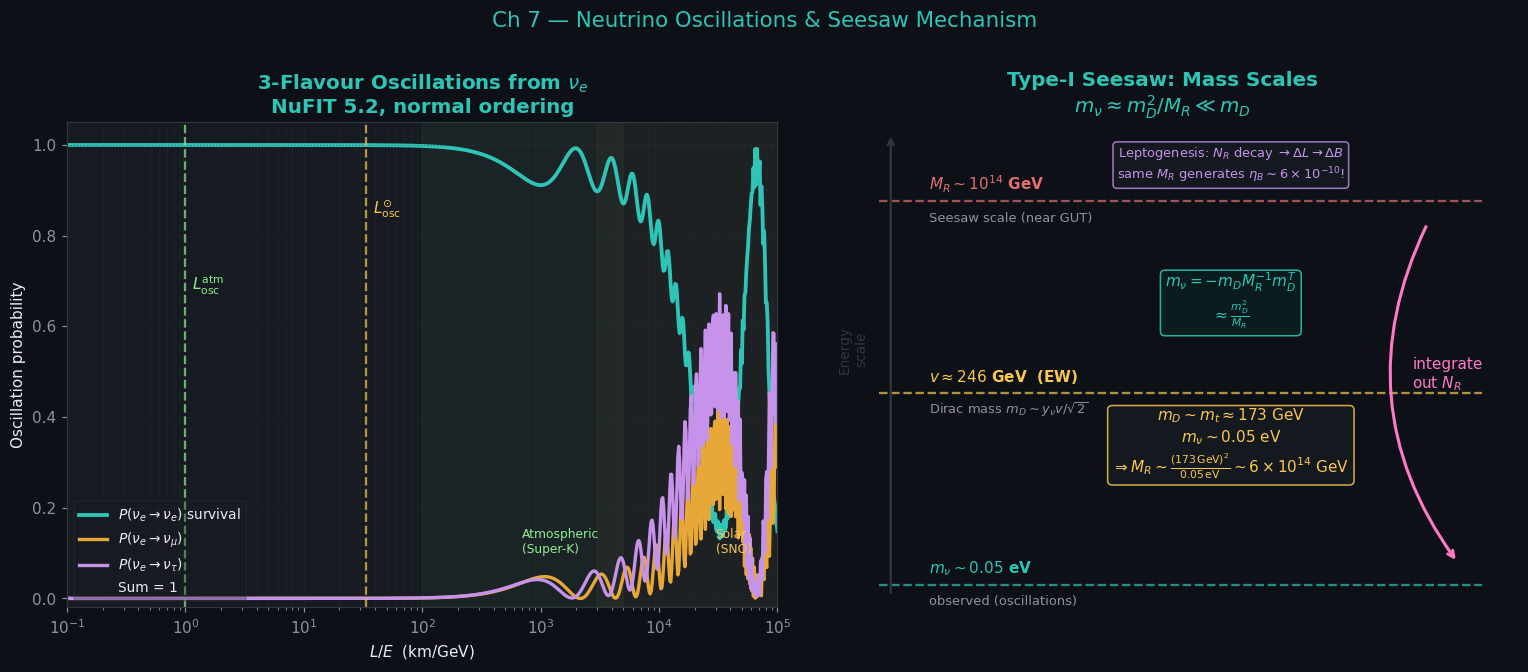

Saved: sm_vis7_neutrinos.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Ch 7 — Neutrino Oscillations & Seesaw Mechanism',
             color=TEAL, fontsize=14, y=1.01)

# PMNS parameters (NuFIT 5.2, normal ordering)
th12 = np.radians(33.44); th23 = np.radians(49.2)
th13 = np.radians(8.57);  dCP  = np.radians(194.0)
dm21 = 7.42e-5;  dm31 = 2.517e-3  # eV^2

c12,s12 = np.cos(th12),np.sin(th12)
c23,s23 = np.cos(th23),np.sin(th23)
c13,s13 = np.cos(th13),np.sin(th13)
eid = np.exp(1j*dCP)

U = np.array([
    [c12*c13,                      s12*c13,                     s13*np.exp(-1j*dCP)],
    [-s12*c23-c12*s23*s13*eid,  c12*c23-s12*s23*s13*eid,   s23*c13],
    [ s12*s23-c12*c23*s13*eid, -c12*s23-s12*c23*s13*eid,   c23*c13],
])

dm_sq = np.array([0, dm21, dm31])

def P_osc(alpha, beta, LoE):
    amp = sum(U[beta,k]*np.conj(U[alpha,k])*np.exp(-1j*1.267*dm_sq[k]*LoE)
              for k in range(3))
    return np.abs(amp)**2

# ── Left: oscillation probabilities ───────────────────────────────────────
ax = axes[0]

LoE = np.logspace(-1, 5, 800)
P_ee  = np.array([P_osc(0,0,x) for x in LoE])
P_emu = np.array([P_osc(0,1,x) for x in LoE])
P_eta = np.array([P_osc(0,2,x) for x in LoE])

ax.semilogx(LoE, P_ee,  color=TEAL,  lw=2.5, label=r'$P(\nu_e\to\nu_e)$ survival')
ax.semilogx(LoE, P_emu, color=ORAN,  lw=2.2, label=r'$P(\nu_e\to\nu_\mu)$')
ax.semilogx(LoE, P_eta, color=PURP,  lw=2.2, label=r'$P(\nu_e\to\nu_\tau)$')
ax.semilogx(LoE, P_ee+P_emu+P_eta, color=EDGE,
            lw=0.8, ls=':', alpha=0.5, label='Sum = 1')

# Solar and atmospheric oscillation lengths
LoE_sol = np.pi / (1.267*dm21) / 1e3
LoE_atm = np.pi / (1.267*dm31) / 1e3
ax.axvline(LoE_sol, color=YELL,  lw=1.5, ls='--', alpha=0.7)
ax.axvline(LoE_atm, color=GREEN, lw=1.5, ls='--', alpha=0.7)
ax.text(LoE_sol*1.15, 0.85, r'$L_{\rm osc}^{\odot}$',  color=YELL,  fontsize=10)
ax.text(LoE_atm*1.15, 0.68, r'$L_{\rm osc}^{\rm atm}$',color=GREEN, fontsize=10)

# Experiment regimes
ax.axvspan(1e2, 5e3, alpha=0.04, color=GREEN)
ax.text(7e2, 0.10, 'Atmospheric\n(Super-K)', color=GREEN, fontsize=8)
ax.axvspan(3e3, 2e5, alpha=0.04, color=YELL)
ax.text(3e4, 0.10, 'Solar\n(SNO)', color=YELL, fontsize=8)

ax.set_xlabel(r'$L/E$  (km/GeV)')
ax.set_ylabel('Oscillation probability')
ax.set_title(r'3-Flavour Oscillations from $\nu_e$' + '\n'
             'NuFIT 5.2, normal ordering')
ax.legend(fontsize=9, labelcolor=TEXT, loc='lower left')
ax.set_xlim(0.1, 1e5); ax.set_ylim(-0.02, 1.05)
ax.grid(True, alpha=0.2, which='both')

# ── Right: seesaw mass scales ──────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_xlim(-0.2, 4.5)
ax2.set_ylim(-1.5, 20)
ax2.axis('off')
ax2.set_title('Type-I Seesaw: Mass Scales\n'
              r'$m_\nu \approx m_D^2/M_R \ll m_D$', color=TEAL)

# Vertical energy axis
ax2.annotate('', xy=(0.35, 19.5), xytext=(0.35, -1.0),
             arrowprops=dict(arrowstyle='->', color=EDGE, lw=1.5))
ax2.text(0.10, 9, 'Energy\nscale', color=EDGE, fontsize=9,
         ha='center', rotation=90)

# Scale levels
scales_ss = [
    (-0.5, r'$m_\nu\sim0.05$ eV',       TEAL,  r'observed (oscillations)'),
    (8.0,  r'$v\approx246$ GeV  (EW)',   YELL,  r'Dirac mass $m_D\sim y_\nu v/\sqrt{2}$'),
    (16.5, r'$M_R\sim10^{14}$ GeV',      RED,   r'Seesaw scale (near GUT)'),
]
for (y, lbl, col, note) in scales_ss:
    ax2.axhline(y, xmin=0.10, xmax=0.95, color=col, lw=1.5, ls='--', alpha=0.7)
    ax2.text(0.6,  y+0.5, lbl,  color=col,  fontsize=10, fontweight='bold')
    ax2.text(0.6,  y-0.9, note, color=DIM,  fontsize=8.5)

# Seesaw relation box
ax2.text(2.6, 11.2,
         r'$m_\nu = -m_D M_R^{-1} m_D^T$' + '\n'
         r'$\approx \frac{m_D^2}{M_R}$',
         ha='center', color=TEAL, fontsize=10,
         bbox=dict(boxstyle='round', fc='#0a1e1e', ec=TEAL, alpha=0.9))

# Numerical example
ax2.text(2.6, 4.5,
         r'$m_D\sim m_t\approx173$ GeV' + '\n'
         r'$m_\nu\sim0.05$ eV' + '\n'
         r'$\Rightarrow M_R\sim\frac{(173\,{\rm GeV})^2}{0.05\,{\rm eV}}\sim6\times10^{14}$ GeV',
         ha='center', color=YELL, fontsize=10,
         bbox=dict(boxstyle='round', fc=SURF, ec=YELL, alpha=0.85))

# Downward arrow (integrate out N_R)
ax2.annotate('', xy=(4.1, 0.5), xytext=(3.9, 15.5),
             arrowprops=dict(arrowstyle='->', color=PINK, lw=2.0,
                             connectionstyle='arc3,rad=0.3'))
ax2.text(3.8, 8.2, 'integrate\nout $N_R$', color=PINK, fontsize=10, ha='left')

# Leptogenesis note
ax2.text(2.6, 17.5,
         r'Leptogenesis: $N_R$ decay $\to\Delta L\to\Delta B$' + '\n'
         r'same $M_R$ generates $\eta_B\sim6\times10^{-10}$!',
         ha='center', color=PURP, fontsize=8.5,
         bbox=dict(boxstyle='round', fc=SURF, ec=PURP, alpha=0.8))

plt.tight_layout()
plt.savefig('sm_vis7_neutrinos.png', dpi=160, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: sm_vis7_neutrinos.png')

In [9]:
import zipfile, os

ZIP_NAME = 'sm_visualizations.zip'
PNG_FILES = [
    'sm_vis1_symmetries.png',
    'sm_vis2_higgs.png',
    'sm_vis3_qcd.png',
    'sm_vis4_anomaly.png',
    'sm_vis5_electroweak.png',
    'sm_vis6_flavour.png',
    'sm_vis7_neutrinos.png',
]

with zipfile.ZipFile(ZIP_NAME, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in PNG_FILES:
        if os.path.exists(fname):
            zf.write(fname)
            print(f'  added: {fname}  ({os.path.getsize(fname)//1024} KB)')
        else:
            print(f'  MISSING: {fname} — run that cell first!')

print(f'\nArchive ready: {ZIP_NAME}  ({os.path.getsize(ZIP_NAME)//1024} KB)')

try:
    from google.colab import files
    files.download(ZIP_NAME)
    print('Download started — check your browser.')
except ImportError:
    print(f'Not running in Colab.  Zip saved at: {os.path.abspath(ZIP_NAME)}')

  added: sm_vis1_symmetries.png  (138 KB)
  added: sm_vis2_higgs.png  (374 KB)
  added: sm_vis3_qcd.png  (188 KB)
  added: sm_vis4_anomaly.png  (172 KB)
  added: sm_vis5_electroweak.png  (128 KB)
  added: sm_vis6_flavour.png  (202 KB)
  added: sm_vis7_neutrinos.png  (215 KB)

Archive ready: sm_visualizations.zip  (1345 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started — check your browser.


---
## Summary

| File | Chapter | Key physics |
|------|---------|-------------|
| `sm_vis1_symmetries.png` | Ch 1 Symmetries | Lorentz $(j_+,j_-)$ reps; SM particle spectrum by spin & mass |
| `sm_vis2_higgs.png`      | Ch 2 Broken Symmetries | 3D Mexican hat potential; mass vs VEV for $W,Z,H,t$ |
| `sm_vis3_qcd.png`        | Ch 3 Strong Force | $\alpha_s(\mu)$ running + data; QCD phase diagram |
| `sm_vis4_anomaly.png`    | Ch 4 Anomalies | $\Gamma(\pi^0\to\gamma\gamma)$ vs $N_c$; $[U(1)]^3$ cancellation |
| `sm_vis5_electroweak.png`| Ch 5 Electroweak | $Z$ partial widths + $N_\nu=3$; $\sin^2\theta_W$ measurements |
| `sm_vis6_flavour.png`    | Ch 6 Flavour | CKM unitarity triangle; $B^0\to J/\psi K_S$ CP asymmetry |
| `sm_vis7_neutrinos.png`  | Ch 7 Neutrinos | 3-flavour oscillations; seesaw mass scales + leptogenesis |